# Day 1: The Engineering Computing Workshop
## Anaconda Environments, Vectorized NumPy, Loading Data & Basic Plotting

**Course:** 1454 - Computing in Civil Engineering  
**Degree:** Master's Degree in Civil Engineering (M.Sc.)

---

### Objectives for Today
Today we focus on three essential skills: **setting up Python environments, managing data with NumPy & Pandas, and creating basic engineering plots**.

1. **Environments & Reproducibility:** Understand what a virtual environment is and how to create your own isolated workspace in Anaconda.
2. **NumPy Vectorized Computing:** Operate directly on vectors and matrices (forces, stresses, coordinates) without slow `for` loops.
3. **Creating DataFrames in Memory:** Build structured tables from scratch using Python dictionaries and lists (`pd.DataFrame`).
4. **Data Concatenation (`pd.concat`):** Merge recorded by different field survey teams into a single DataFrame.
5. **Loading Engineering Files:** Read `.csv`, `.xlsx`, and commented `.txt` dataloggers effortlessly with Pandas.
6. **Calculating Columns & Filtering Data:** Compute new physical columns ($\sigma = F/A$) and filter rows using logical conditions.
7. **Basic Technical Plotting with Matplotlib:** Generate clean line plots, scatter charts, and bar plots with engineering units and threshold lines.

---
### Section 1: Anaconda Environments 


#### Day 1 Setup: Creating Your Environment (One by One)

Open **Anaconda Prompt** (from the Windows Start Menu, or from Anaconda Navigator $\rightarrow$ *Environments* $\rightarrow$ *base* $\rightarrow$ *Open Terminal*):

```bash
# Step 1: Create an environment named 'cice' with Python 3.11
conda create -n cice python=3.11 -y

# Step 2: Step inside (activate) your new environment
conda activate cice

# Step 3: Install Jupyter Notebook and essential libraries one by one:
pip install notebook      # Installs Jupyter Notebook inside this environment
pip install numpy         # High-performance vectors and matrices
pip install pandas        # DataFrames and tabular file ingestion
pip install matplotlib    # Technical engineering plotting
pip install openpyxl      # Support for reading Excel (.xlsx) files
```

> **Adding libraries later in the course (Day 2):**
> An environment is never closed. When you need advanced statistics or machine learning later, simply activate your environment (`conda activate cice`) and run:
> `pip install scipy` and `pip install scikit-learn`.

---

#### How to Launch Jupyter Notebook

* **For Today (Day 1):**
  In the same Anaconda Prompt terminal where you activated `cice`, launch Jupyter directly:
  ```bash
  jupyter notebook
  ```
  *(Jupyter will open in your web browser, already linked to your `cice` environment with all libraries loaded).*

* **From Day 2 Onwards (100% Visual via Anaconda Navigator):**
  No terminal commands needed!
  1. Open **Anaconda Navigator**.
  2. In the top dropdown (**Applications on:**), select **`cice`**.
  3. Locate the **Jupyter Notebook** tile and click the blue **Launch** button.
  4. Your browser will open with everything pre-loaded and ready.

---

#### Installing Libraries Directly Inside Jupyter (`%pip install`)

If you ever encounter a `ModuleNotFoundError` during a lab, you do not need to open a terminal or restart your session. Simply create a new code cell and run:

```python
%pip install <library_name>
```

> **Why use `%pip` instead of `!pip`?**
> * `!pip` calls your operating system shell, which might accidentally install into a different Python version installed on your machine.
> * `%pip` is the official **IPython magic command** that guarantees the package is installed into the exact environment currently powering this notebook.

In [31]:
# Interactive Package Installation Example:
# If a library is ever missing, uncomment the line below and run this cell:
# %pip install openpyxl


---
### Section 2: Standard Library Imports
We start by importing the essential Python libraries (numpy, pandas, matplotlib) using their common abbreviations::

In [32]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
### Section 3: NumPy — Vectorized Computing & Matrices 

In civil engineering, physical quantities are vectors (forces, coordinates, stresses).  
NumPy allows mathematical operations across entire arrays simultaneously.

In [33]:
# 1. 1D Array (Vector of forces in metric tonnes)
forces_t = np.array([12.5, 18.0, 24.5, 30.2, 45.0, 52.8])

# 2. Direct vector arithmetic: convert tonnes to kN (1 t = 9.81 kN)
forces_kN = forces_t * 9.81

print("Forces in tonnes:     ", forces_t)
print("Forces in kilonewtons:", np.round(forces_kN, 2))

Forces in tonnes:      [12.5 18.  24.5 30.2 45.  52.8]
Forces in kilonewtons: [122.62 176.58 240.34 296.26 441.45 517.97]


In [34]:
# 3. Stress calculation: sigma = F / A
# Cylindrical specimen diameter d = 150 mm = 0.15 m
radius = 0.15 / 2
area_m2 = np.pi * (radius ** 2)

# Vectorized stress calculation in Megapascals (1 MPa = 1000 kN/m2)
stresses_MPa = forces_kN / (area_m2 * 1000.0)

print(f"Specimen cross-sectional area: {area_m2:.6f} m²")
print("Resulting compressive stresses (MPa):", np.round(stresses_MPa, 2))

Specimen cross-sectional area: 0.017671 m²
Resulting compressive stresses (MPa): [ 6.94  9.99 13.6  16.76 24.98 29.31]


In [36]:
# 4. 2D Array (Matrix): 2D Coordinate Transformation
# A 3x2 matrix of structural nodes (X, Y in meters)
nodes = np.array([
    [0.0, 0.0],
    [5.0, 0.0],
    [2.5, 4.33]
])

# Translation vector: shift 10m East, 20m North
shift = np.array([10.0, 20.0])

nodes_shifted = nodes + shift
print("Original nodes:", nodes)
print("Shifted nodes:", nodes_shifted)

Original nodes: [[0.   0.  ]
 [5.   0.  ]
 [2.5  4.33]]
Shifted nodes: [[10.   20.  ]
 [15.   20.  ]
 [12.5  24.33]]


---
### Section 4: Introduction to Pandas DataFrames (Creating Tables in Memory)

Before reading external files from disk, let's understand what a **Pandas DataFrame** actually is:  
A **DataFrame** is a 2D labeled data structure (like an Excel table in Python memory). Unlike NumPy matrices which must contain data of the same type, a DataFrame can combine text, numbers, and booleans across columns.

We can create DataFrames directly in memory using standard Python data structures:

1. **From a Dictionary of Lists (Column-oriented)**: The keys become column headers, and each list becomes the column's data values. *(Most common and natural in Python)*.
2. **From a List of Lists (Row-oriented)**: Each inner list represents a single row of measurements. We supply column headers with the `columns=[...]` argument.

In [37]:
# 1. Creating a DataFrame from a Dictionary (Column-by-column)
materials_dict = {
    'Material': ['Concrete C25/30', 'Structural Steel S355', 'Timber C24', 'Masonry'],
    'Density_kg_m3': [2400, 7850, 420, 1800],
    'Elastic_Modulus_GPa': [31.0, 210.0, 11.0, 5.0],
    'Characteristic_Strength_MPa': [25.0, 355.0, 24.0, 6.0]
}

df_materials = pd.DataFrame(materials_dict)

# Display DataFrame in Jupyter
df_materials


,Material,Density_kg_m3,Elastic_Modulus_GPa,Characteristic_Strength_MPa
0,Concrete C25/30,2400,31.0,25.0
1,Structural Steel S355,7850,210.0,355.0
2,Timber C24,420,11.0,24.0
3,Masonry,1800,5.0,6.0


In [38]:
# 2. Creating a DataFrame from a List of Lists (Row-by-row)
beams_list = [
    ['B-101', 6.0, 14.2, 'Passed'],
    ['B-102', 8.5, 22.8, 'Passed'],
    ['B-103', 5.0, 18.5, 'Review'],
    ['B-104', 10.0, 31.0, 'Failed']
]
beam_columns = ['Beam_ID', 'Span_m', 'Deflection_mm', 'QC_Status']

df_beams = pd.DataFrame(beams_list, columns=beam_columns)

# Display DataFrame in Jupyter
df_beams

,Beam_ID,Span_m,Deflection_mm,QC_Status
0,B-101,6.0,14.2,Passed
1,B-102,8.5,22.8,Passed
2,B-103,5.0,18.5,Review
3,B-104,10.0,31.0,Failed


#### Hands-on Exercise: Build a Concrete Quality Control DataFrame

A materials testing laboratory tests 4 precast concrete elements. Complete the exercise below:
1. Create a DataFrame `df_qc` from the provided dictionary of laboratory measurements.
2. Add a new column `'Pass_Strength'` checking if the 28-day compressive strength is $\ge 30.0\text{ MPa}$.

In [ ]:
# Laboratory measurements dictionary
qc_measurements = {
    'Element_ID': ['PC-01', 'PC-02', 'PC-03', 'PC-04'],
    'Water_Cement_Ratio': [0.42, 0.48, 0.52, 0.40],
    'Slump_cm': [8.0, 12.5, 15.0, 7.5],
    'Strength_28d_MPa': [35.4, 29.2, 26.8, 38.1]
}

# 1. Build DataFrame from dictionary


# 2. Add calculated boolean column (True if Strength >= 30.0 MPa)


# Display DataFrame in Jupyter



---
### Section 5: Combining Multiple Datasets with pd.concat

In civil engineering, measurements are often recorded by different field survey teams or sensor stations.  
The function **`pd.concat([df1, df2, ...], ignore_index=True)`** combines multiple DataFrames vertically into one master table.

In [56]:
# Example: Two independent survey teams inspect structural cracks on a bridge
team_north = pd.DataFrame({
    'Structure_ID': ['Bridge_N1', 'Bridge_N2'],
    'Span': ['North Span', 'North Span'],
    'Crack_Width_mm': [0.15, 0.40]
})

team_south = pd.DataFrame({
    'Structure_ID': ['Bridge_S1', 'Bridge_S2'],
    'Span': ['South Span', 'South Span'],
    'Crack_Width_mm': [0.10, 0.85]
})

# Combine both inspection teams into a single master report (2 + 2 = 4 rows):
df_inspections = pd.concat([team_north, team_south], ignore_index=True)

print("Master Bridge Inspection Report:")
print(df_inspections)

Master Bridge Inspection Report:
  Structure_ID        Span  Crack_Width_mm
0    Bridge_N1  North Span            0.15
1    Bridge_N2  North Span            0.40
2    Bridge_S1  South Span            0.10
3    Bridge_S2  South Span            0.85


---
### Section 6: Loading Engineering Data: CSV, Excel, and TXT
Pandas can read any structured external format from disk into a **`DataFrame`**.

In [40]:
# Resolve data folder path
data_dir = "../data" if os.path.exists("../data") else "Clases_Practicas/data"

# A. Read standard CSV
df_projects = pd.read_csv(os.path.join(data_dir, "construction_projects_budget.csv"))

df_projects.head()


,Project_ID,Project_Name,Typology,Contractor,Tender_Budget_kEUR,Final_Cost_kEUR,Estimated_Months,Actual_Months,Cost_Deviation_pct
0,P-101,Viaducto del Besaya,Structures/Bridges,Infraestructuras_Global,29297.2,39549.3,29,40,34.99
1,P-102,Puente Arco sobre Rio Deva,Structures/Bridges,Infraestructuras_Global,20260.3,21905.4,21,24,8.12
2,P-103,Paso Superior FFCC km 14,Structures/Bridges,Iberica_Obras_Civiles,4575.5,4300.9,18,19,-6.00
3,P-104,Pasarela Peatonal Bahia,Structures/Bridges,Infraestructuras_Global,16414.6,13086.8,22,22,-20.27
4,P-105,Puente Mixto Autovia A-8,Structures/Bridges,Contrata_Norte_SA,15189.5,13498.7,21,21,-11.13


In [41]:
# B. Read multi-sheet Excel
df_specs = pd.read_excel(os.path.join(data_dir, "concrete_strength.xlsx"), sheet_name="Especificaciones")

df_specs

,Parametro,Valor,Unidad,Normativa
0,Tipo de Hormigon,HA-30/B/20/IIa,-,Codigo Estructural
1,Resistencia Caracteristica Especificada (fck),30,MPa,Art. 33.1
2,Resistencia Media Esperada (fcm),38,MPa,fcm = fck + 8
3,Diametro Probeta Cilindrica,150,mm,UNE-EN 12390-1
4,Area Seccion Transversal,176.71,cm2,A = pi * d^2 / 4
5,Criterio Aceptacion Lote (cuantil 5%),30,MPa,f1 >= fck


In [42]:
# C. Read Datalogger TXT skipping metadata comments (#)
df_sensor = pd.read_csv(
    os.path.join(data_dir, "bridge_sensor_shm.txt"),
    sep='\t',
    comment='#',
    names=['Timestamp', 'Strain_uE', 'Temp_C', 'Tilt_deg', 'Status']
)

df_sensor.head()

,Timestamp,Strain_uE,Temp_C,Tilt_deg,Status
0,2025-06-01 00:00:00,-35.98,11.19,0.0219,OK
1,2025-06-01 01:00:00,-34.24,10.84,0.0200,OK
2,2025-06-01 02:00:00,-57.68,8.47,0.0188,OK
3,2025-06-01 03:00:00,-82.05,7.04,0.0184,OK
4,2025-06-01 04:00:00,-68.97,8.54,0.0173,OK


---
### Section 7: Calculating New Columns and Filtering Rows

In engineering data workflows, raw datasets rarely contain every metric we need for decision-making.  
With Pandas, we create new calculated columns directly using vectorized arithmetic across existing columns.

Let's evaluate our 80 public infrastructure projects (`df_projects`):
1. Compute project schedule delay in months: $\text{Delay} = \text{Actual Months} - \text{Estimated Months}$.
2. Compute budget cost overrun in Million Euros (M€): $\text{Overrun} = (\text{Final Cost} - \text{Tender Budget}) / 1000$.
3. Filter critical bridge projects experiencing delays greater than 6 months using boolean conditions (`&`).

In [45]:
# 1. Calculate project schedule delay in months
df_projects['Delay_Months'] = df_projects['Actual_Months'] - df_projects['Estimated_Months']

# 2. Calculate budget cost overrun in Million Euros (M€) by dividing kEUR by 1,000
df_projects['Cost_Overrun_MEUR'] = ((df_projects['Final_Cost_kEUR'] - df_projects['Tender_Budget_kEUR']) / 1000.0).round(2)

# 3. Filter critical bridge projects with significant delay (> 6 months)
delayed_bridges = df_projects[
    (df_projects['Typology'] == 'Structures/Bridges') & (df_projects['Delay_Months'] > 6)
]

print(f"Total infrastructure projects evaluated: {len(df_projects)}")
print(f"Bridge projects with delays > 6 months: {len(delayed_bridges)}")
delayed_bridges[['Project_ID', 'Project_Name', 'Contractor', 'Delay_Months', 'Cost_Overrun_MEUR']].head()

Plant A tests below 35 MPa: 21


,Sample_ID,Test_Date,Plant,Failure_Load_kN,Stress_MPa
12,CYL-1013,2026-01-07,Planta_A_CanteraNorte,611.0,34.58
13,CYL-1014,2026-01-07,Planta_A_CanteraNorte,573.8,32.47
15,CYL-1016,2026-01-08,Planta_A_CanteraNorte,614.4,34.77
27,CYL-1028,2026-01-14,Planta_A_CanteraNorte,443.3,25.09
28,CYL-1029,2026-01-15,Planta_A_CanteraNorte,577.9,32.70


---
### Section 8: Basic Technical Plotting with Matplotlib 
We visualize data trends directly using lines, scatter plots, and bar charts.

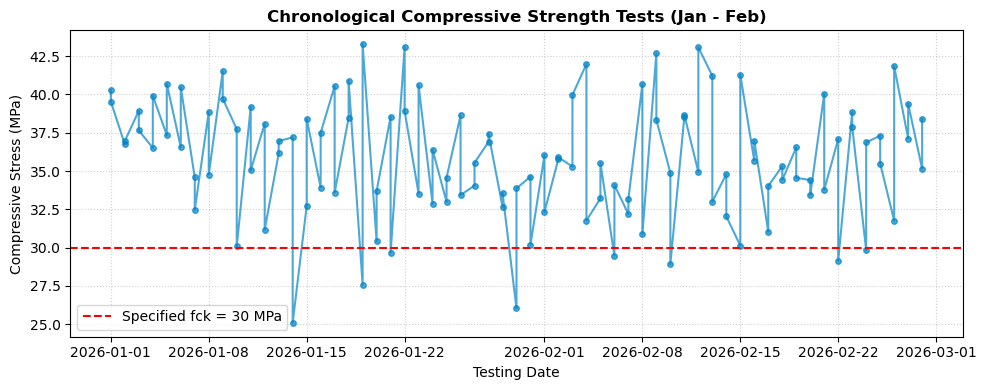

In [46]:
# 1. Line plot: Failure loads over time
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(pd.to_datetime(df_total_tests['Test_Date']), df_total_tests['Stress_MPa'], 
        marker='o', markersize=4, linestyle='-', color='#0284C7', alpha=0.7)

# Technical threshold line
ax.axhline(30.0, color='red', linestyle='--', linewidth=1.5, label='Specified fck = 30 MPa')

ax.set_title('Chronological Compressive Strength Tests (Jan - Feb)', fontsize=12, fontweight='bold')
ax.set_xlabel('Testing Date', fontsize=10)
ax.set_ylabel('Compressive Stress (MPa)', fontsize=10)
ax.legend(loc='lower left')
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

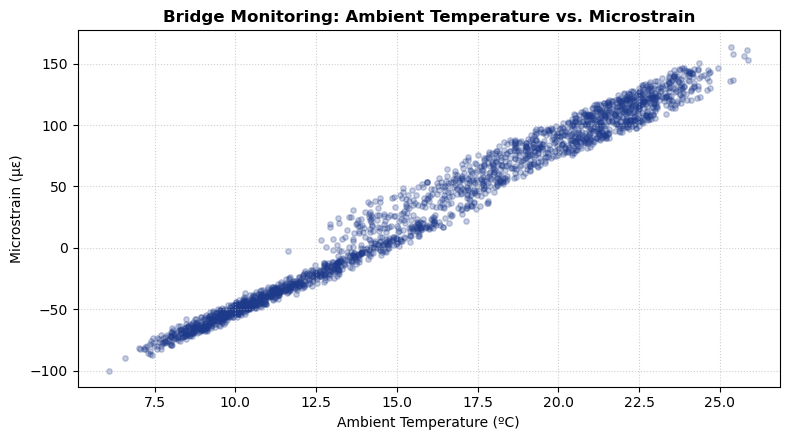

In [47]:
# 2. Scatter plot: Comparing Ambient Temperature vs. Lower-Chord Bridge Microstrain
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.scatter(df_sensor['Temp_C'], df_sensor['Strain_uE'], color='#1E3A8A', alpha=0.25, s=15)

ax.set_title('Bridge Monitoring: Ambient Temperature vs. Microstrain', fontsize=12, fontweight='bold')
ax.set_xlabel('Ambient Temperature (ºC)', fontsize=10)
ax.set_ylabel('Microstrain (µε)', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

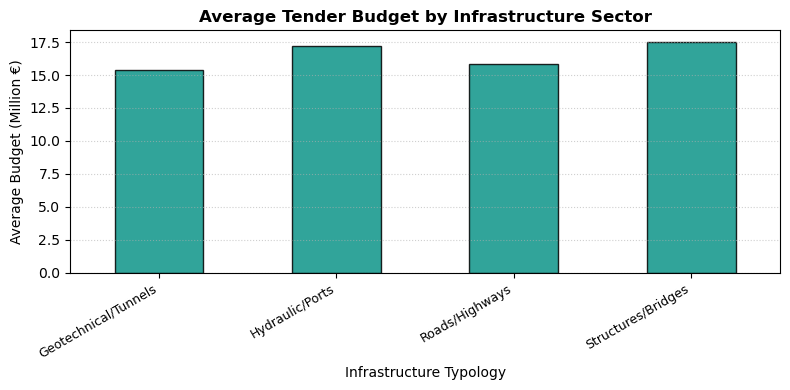

In [25]:
# 3. Bar chart: Average budget by infrastructure sector
mean_budgets = df_projects.groupby('Typology')['Tender_Budget_kEUR'].mean() / 1000.0  # in Million EUR

fig, ax = plt.subplots(figsize=(8, 4))
mean_budgets.plot(kind='bar', ax=ax, color='#0D9488', edgecolor='black', alpha=0.85)

ax.set_title('Average Tender Budget by Infrastructure Sector', fontsize=12, fontweight='bold')
ax.set_xlabel('Infrastructure Typology', fontsize=10)
ax.set_ylabel('Average Budget (Million €)', fontsize=10)
ax.grid(axis='y', linestyle=':', alpha=0.6)

plt.xticks(rotation=30, ha='right', fontsize=9)
plt.tight_layout()
plt.show()

---
### YOUR TURN: The Day 1 Hands-on Challenge

Now it is your turn to build a clean notebook from scratch without any prewritten template!

1. Open a **New Notebook** (`File -> New -> Notebook`) and name it `Lab01_DataWrangling_YourName.ipynb`.
2. Import `numpy as np`, `pandas as pd`, and `matplotlib.pyplot as plt`.
3. Ingest `concrete_batch_january.csv` and `concrete_batch_february.csv` and concatenate them using `pd.concat`.
4. Calculate the stress column `Stress_MPa`.
5. Group by `Plant` and compute the total number of tests and average load.
6. Generate a bar chart showing the average failure load per plant and save it to disk with `plt.savefig('my_plant_comparison.png', dpi=200)`.

